In [1]:
import numpy as np
import os
import astropy.units as u
import astropy.constants as const
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import h5py

import json

from synch_emission_functions import b_hadr, b_coul_p, b_adiab, b_synch, b_ic_photon, b_ic_star, b_coul_e, mp, c, me

In [2]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"
# load the bowshock config
bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

In [21]:

# pp_arr = np.logspace(0.8, 4, 200) * u.GeV / c  # energy grid for protons
# pp_arr = (pp_arr / (mp * c)).to_value(
#     u.dimensionless_unscaled
# )  # normalised momentum wrt protons
pp_arr = np.logspace(0, 4, 200)
print(
    f"Minimum & maximum of normalised momentum (protons): {(pp_arr.min() * mp * c**2).to(u.GeV):.5e}, {(pp_arr.max() * mp * c**2).to(u.GeV):.5e}"
)

# pe_arr = np.logspace(-5, 4, 200) * u.GeV / c # energy grid for electrons
# pe_arr = (pe_arr / (me * c)).to_value(
#     u.dimensionless_unscaled
# )  # normalised momentum wrt protons
pe_arr = np.logspace(2, 7, 200)
print(
    f"Minimum & maximum of normalised momentum (electrons): {(pe_arr.min() * me * c**2).to(u.GeV):.5e}, {(pe_arr.max() * me * c**2).to(u.GeV):.5e}"
)

Minimum & maximum of normalised momentum (protons): 9.38272e-01 GeV, 9.38272e+03 GeV
Minimum & maximum of normalised momentum (electrons): 5.10999e-02 GeV, 5.10999e+03 GeV


In [22]:
alpha_inj_p = 4.2
alpha_inj_e = 4.2

dens_val = 1e-25 * (u.g / u.cm**3)
mag_val = 1 * u.uG
vel_val = 1000 * u.km/u.s
r_pos = 5 * u.pc

In [23]:
cool_proton_settings = {
    'b_hadr' : {
        'label' : r"$b_\mathrm{hadr}$ / s$^{-1}$",
        'color' : 'r'
    },
    'b_coul' : {
        'label' : r"$b_\mathrm{Coul}$ / s$^{-1}$",
        'color' : 'b'
    },
    'b_adiab' : {
        'label' : r"$b_\mathrm{adiab}$ / s$^{-1}$",
        'color' : 'g'
    },
}

b_hadr 1 / s
b_coul 1 / s
b_adiab 1 / s


Text(0.5, 1.0, '$\\alpha_{inj}$ = 4.2, $\\rho$ = 1e-25 g / cm3, $v$ = 1000 km / s')

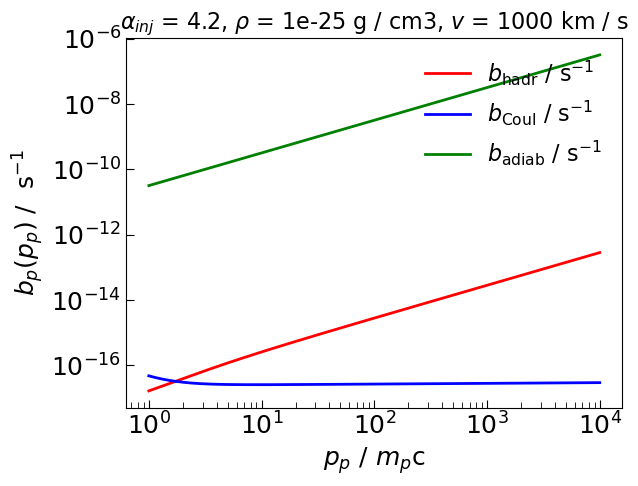

In [24]:
fig, ax = plt.subplots()


for cool_prot in cool_proton_settings:
    # calculate
    if cool_prot == 'b_hadr':
        b_cool = b_hadr(pp_arr, dens_val)
    elif cool_prot == 'b_coul':
        b_cool = b_coul_p(pp_arr, dens_val)
    elif cool_prot == 'b_adiab':
        b_cool = b_adiab(pp_arr, vel_val, vstar=40 * u.km/u.s)

    print(cool_prot, b_cool.unit)

    ax.loglog(pp_arr, b_cool, label=cool_proton_settings[cool_prot]['label'], color=cool_proton_settings[cool_prot]['color'], lw=2.0)

ax.set_xlabel(r"$p_p$ / $m_p$c", fontsize=18)
ax.set_ylabel(r"$b_p(p_p)$ /  s$^{-1}$", fontsize=18)
# ax.set_ylabel(r"$\hat{f} \; (p)$ / a. u. ", fontsize=18)

# ax.set_xlim(1e2, 1e4)
# ax.set_ylim(ymin=1e-14, ymax=1)

ax.tick_params(axis='both', direction="in", which='major', size=6, labelsize=18)
ax.tick_params(axis='both', direction="in", which='minor', size=4, labelsize=16)

ax.legend(loc="upper right", prop={"size":16}, frameon=False)
# leg1 = ax.legend(handles=alpha_inj_handles, loc="upper right", prop={"size":14}, bbox_to_anchor=[1.38, 1.02])
# ax.add_artist(leg1)
# ax.legend(handles=alpha_e_handles, loc="lower right", prop={"size":14}, bbox_to_anchor=[1.38, -0.02])

ax.set_title(fr"$\alpha_{{inj}}$ = {alpha_inj_p}, $\rho$ = {dens_val:.0e}, $v$ = {vel_val:.0f}", fontsize=16)

# fig.savefig(f"{fig_dir}/steady_state_spectra_proton.pdf", dpi=150, bbox_inches='tight')

In [25]:
cool_electron_settings = {
    'b_synch' : {
        'label' : r"$b_\mathrm{synch}$ / s$^{-1}$",
        'color' : 'r'
    },
    'b_coul' : {
        'label' : r"$b_\mathrm{Coul}$ / s$^{-1}$",
        'color' : 'b'
    },
    'b_adiab' : {
        'label' : r"$b_\mathrm{adiab}$ / s$^{-1}$",
        'color' : 'g'
    },
    'b_ic' : {
        'label' : r"$b_\mathrm{IC}$ / s$^{-1}$",
        'color' : 'm'
    },
}

1 / s
1 / s
1 / s
1 / s


Text(0.5, 1.0, '$\\alpha_{inj}$ = 4.2, $\\rho$ = 1e-25 g / cm3, $v$ = 1000 km / s')

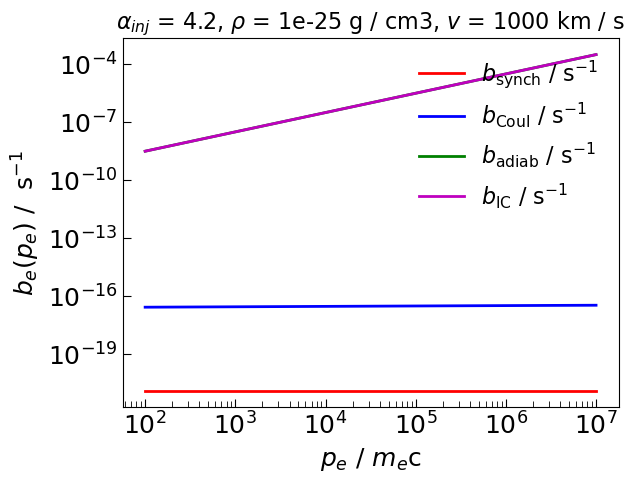

In [26]:
fig, ax = plt.subplots()


for cool_electr in cool_electron_settings:
    # calculate
    if cool_electr == 'b_synch':
        b_cool = b_synch(pe_arr, mag_val)
    elif cool_electr == 'b_coul':
        b_cool = b_coul_p(pe_arr, dens_val)
    elif cool_electr == 'b_adiab':
        b_cool = b_adiab(pe_arr, vel_val, vstar=40 * u.km/u.s)
    elif cool_electr == 'b_ic':
        b_ic = b_ic_photon(pe_arr)
        
        b_ic += b_ic_star(pe_arr, Tstar=1e4 * u.K, r_pos=r_pos)
    print(b_cool.unit)

    ax.loglog(pe_arr, b_cool, label=cool_electron_settings[cool_electr]['label'], color=cool_electron_settings[cool_electr]['color'], lw=2.0)

ax.set_xlabel(r"$p_e$ / $m_e$c", fontsize=18)
ax.set_ylabel(r"$b_e(p_e)$ /  s$^{-1}$", fontsize=18)
# ax.set_ylabel(r"$\hat{f} \; (p)$ / a. u. ", fontsize=18)

# ax.set_xlim(1e2, 1e4)
# ax.set_ylim(ymin=1e-14, ymax=1)

ax.tick_params(axis='both', direction="in", which='major', size=6, labelsize=18)
ax.tick_params(axis='both', direction="in", which='minor', size=4, labelsize=16)

ax.legend(loc="upper right", prop={"size":16}, frameon=False)
# leg1 = ax.legend(handles=alpha_inj_handles, loc="upper right", prop={"size":14}, bbox_to_anchor=[1.38, 1.02])
# ax.add_artist(leg1)
# ax.legend(handles=alpha_e_handles, loc="lower right", prop={"size":14}, bbox_to_anchor=[1.38, -0.02])

ax.set_title(fr"$\alpha_{{inj}}$ = {alpha_inj_p}, $\rho$ = {dens_val:.0e}, $v$ = {vel_val:.0f}", fontsize=16)

# fig.savefig(f"{fig_dir}/steady_state_spectra_proton.pdf", dpi=150, bbox_inches='tight')